In [15]:
#  Imports
import random
import numpy as np
import pandas as pd 
import matplotlib.pyplot as plt
import seaborn as sns
from pathlib import Path
from collections import defaultdict
import matplotlib as mpl
import CCC_utils as CCC

# Keep text editable in AI
mpl.rcParams['pdf.fonttype'] = 42
mpl.rcParams['ps.fonttype']  = 42
mpl.rcParams['svg.fonttype'] = 'none'


In [16]:
# AGM gene-list folder
main_dir = Path(f"C:/Users/gabri/Documents/Data_projects/MCcharactertization/ROSMAP/Top_sets/Set309/CellCellComms")
#main_dir = Path(f"/Users/ga0028vi/Documents/MCcharactertization/ROSMAP/Top_sets/Set309/CellCellComms")

padded_csv = main_dir / "CCC_genes" / "PLS_significant_gene_lists_padded.csv"
hvg_dir = main_dir.parent / "_set_data"
cpdb_dir = main_dir.parents[2]/ "CellphoneDb_test/v5.0.0/cellphonedb"

out_dir = main_dir / "CCC_nulls"

Path(out_dir).mkdir(parents=True, exist_ok=True)
res_dir = out_dir / "results"
res_dir.mkdir(parents=True, exist_ok=True)

real_res_dir = main_dir / "CCC_results"

n_null = 10000
seed = 123 

In [17]:
df_true = pd.read_csv(padded_csv)

true_modules = {}
sizes_by_subtype = {}

for col in df_true.columns:
    base, _k = col.split("_Cluster_")
    major = base.split("_", 1)[0]
    subtype = base.split("_", 1)[1]

    genes = set(df_true[col].dropna().astype(str))
    size = len(genes)

    true_modules[col] = genes
    sizes_by_subtype.setdefault((major, subtype), []).append((col, size))

cluster_order = list(true_modules.keys())  # keep same order for matrices
print(f"{len(cluster_order)} AGMs loaded from true AGM list.")
print(f"{sum(len(v) for v in sizes_by_subtype.values())} AGM sizes stored for null sampling.")

24 AGMs loaded from true AGM list.
24 AGM sizes stored for null sampling.


In [18]:
# Read in hvg gene lists from ref files
hvgs_by_major = {}

for txt in Path(hvg_dir).glob("*_ref_genes.txt"):
    major = txt.stem.replace("_ref_genes", "")
    hvgs_by_major[major] = txt.read_text(encoding="utf-8").splitlines()

print("HVGs loaded for majors:", ", ".join(sorted(hvgs_by_major)))

HVGs loaded for majors: Astrocytes, Excitatory, Immune, Inhibitory, OPCs, Oligodendrocytes, Vasculature


In [19]:
# Load the CellPhoneDB tables
protein_df = pd.read_csv(cpdb_dir / "protein_table.csv")[["protein_name", "protein_multidata_id"]]
gene_df = pd.read_csv(cpdb_dir / "gene_table.csv")[["protein_name", "gene_name"]].drop_duplicates()
complex_composition_df = pd.read_csv(cpdb_dir / "complex_composition_table.csv")[["complex_multidata_id", "protein_multidata_id"]]
interaction_df = pd.read_csv(cpdb_dir / "interaction_table.csv")

# One row per protein with its gene name (proteins without a gene are dropped)
protein_genes = protein_df.merge(gene_df, on="protein_name").dropna(subset=["gene_name"])

# Single proteins: multidata ID -> {gene}
protein_map = protein_genes.groupby("protein_multidata_id")["gene_name"].apply(set).to_dict()

# Complexes: multidata ID -> {genes of all its component proteins}
complex_genes = complex_composition_df.merge(protein_genes, on="protein_multidata_id")
complex_map = complex_genes.groupby("complex_multidata_id")["gene_name"].apply(set).to_dict()

# One lookup for any interaction partner, whether single protein or complex
md2genes = {**protein_map, **complex_map}

print(f"Mapped {len(protein_map)} single proteins and {len(complex_map)} complexes")

# Turn each CellPhoneDB interaction into a record of gene sets, grouped by class.
# Each interaction is stored once; compute_ccc_matrices() handles directionality.
interaction_df["classification"] = interaction_df["classification"].fillna("")
records_by = defaultdict(list)

for _, row in interaction_df.iterrows():
    id_a, id_b = row["multidata_1_id"], row["multidata_2_id"]
    partner_a, partner_b = md2genes.get(id_a), md2genes.get(id_b)

    # Skip interactions with a partner we couldn't map to genes (none in CellPhoneDB v5)
    if partner_a is None or partner_b is None:
        continue

    records_by[row["directionality"]].append(
        (id_a, id_b, partner_a, partner_b, row["classification"], row["id_cp_interaction"])
    )

n_resolved = sum(len(records) for records in records_by.values())
print(f"Resolved {n_resolved} / {len(interaction_df)} interactions:")
for cat, records in records_by.items():
    print(f"  {cat}: {len(records)}")

Mapped 1355 single proteins and 362 complexes
Resolved 2911 / 2911 interactions:
  Adhesion-Adhesion: 242
  Ligand-Receptor: 2508
  Receptor-Receptor: 28
  Gap-Gap: 10
  Ligand-Ligand: 123


In [20]:
# quick test for one null
rng = random.Random(seed)
one_null = CCC.draw_one_null(sizes_by_subtype, hvgs_by_major, rng)
len(one_null), list(one_null.keys())[:3]

(24,
 ['Excitatory_ExcL45RORBGABRG1_Cluster_0',
  'Excitatory_ExcL45RORBGABRG1_Cluster_7',
  'Excitatory_ExcL45RORBGABRG1_Cluster_8'])

In [7]:
rng = random.Random(seed)
order = cluster_order
classes = list(records_by.keys())

null_total_connections = {cat: [] for cat in classes}
null_total_interactions = {cat: [] for cat in classes}

print("Running null models...")

for iteration in range(n_null):
    null_modules = CCC.draw_one_null(sizes_by_subtype, hvgs_by_major, rng)

    for cat, records in records_by.items():
        directed = cat == "Ligand-Receptor"
        binary, _ = CCC.make_matrices(records, null_modules, cluster_order, directed)

        # Undirected matrices are mirrored, so count each AGM pair once (upper triangle)
        n_connections = binary.sum() if directed else np.triu(binary).sum()
        null_total_connections[cat].append(int(n_connections))

    if (iteration + 1) % max(1, n_null // 10) == 0:
        print(f"{iteration + 1}/{n_null} nulls done...")

print("Null modelling complete.")

Running null models...
1000/10000 nulls done...
2000/10000 nulls done...
3000/10000 nulls done...
4000/10000 nulls done...
5000/10000 nulls done...
6000/10000 nulls done...
7000/10000 nulls done...
8000/10000 nulls done...
9000/10000 nulls done...
10000/10000 nulls done...
Null modelling complete.


In [8]:
# Compare the true connection totals (from notebook b) with the null distributions
true_summary = pd.read_csv(real_res_dir / "CCC_summary.csv")
true_connections = true_summary.set_index("directionality")["total_cluster_connections"]

rows = []

for cat, values in null_total_connections.items():
    null_values = np.array(values)
    lo, hi = np.percentile(null_values, [2.5, 97.5])

    # Save the full null distribution so it can be re-plotted without rerunning the nulls
    name = cat.replace("-", "_")
    pd.DataFrame({"total_connections": null_values}).to_csv(res_dir / f"null_total_connections_{name}.csv", index=False)

    rows.append({
        "directionality": cat,
        "N_null": len(null_values),
        "true_total_connections": int(true_connections[cat]),
        "null_total_connections_CI_low_2p5": lo,
        "null_total_connections_CI_hi_97p5": hi,
    })

thresholds_df = pd.DataFrame(rows)
thresholds_df.to_csv(res_dir / "binary_null_thresholds_with_true_counts.csv", index=False)
thresholds_df

,directionality,N_null,true_total_connections,null_total_connections_CI_low_2p5,null_total_connections_CI_hi_97p5
0,Adhesion-Adhesion,10000,12,2.0,17.0
1,Ligand-Receptor,10000,94,27.0,65.0
2,Receptor-Receptor,10000,0,0.0,4.0
3,Gap-Gap,10000,1,0.0,6.0
4,Ligand-Ligand,10000,0,0.0,3.0


In [9]:
# Read true observed CCC summary that you already saved
true_summary = pd.read_csv(real_res_dir / "CCC_summary.csv")

rows = []

for cat in classes:
    safe_cat = cat.replace("-", "_")

    # Null distribution from null modelling
    null_arr = np.array(null_total_connections[cat], dtype=float)

    lo, hi = np.percentile(null_arr, [2.5, 97.5])

    # True observed binary connectivity from saved CCC summary
    true_total = int(
        true_summary.loc[
            true_summary["directionality"] == cat,
            "total_cluster_connections"
        ].iloc[0]
    )

    # Save the null distribution for plotting later
    pd.DataFrame({
        "total_connections": null_arr
    }).to_csv(
        res_dir / f"null_total_connections_{safe_cat}.csv",
        index=False
    )

    rows.append({
        "directionality": cat,
        "N_null": len(null_arr),
        "true_total_connections": true_total,
        "null_total_connections_CI_low_2p5": lo,
        "null_total_connections_CI_hi_97p5": hi,
    })

thresholds_df = pd.DataFrame(rows)
thresholds_df.to_csv(
    res_dir / "binary_null_thresholds_with_true_counts.csv",
    index=False
)

thresholds_df

,directionality,N_null,true_total_connections,null_total_connections_CI_low_2p5,null_total_connections_CI_hi_97p5
0,Adhesion-Adhesion,10000,12,2.0,17.0
1,Ligand-Receptor,10000,94,27.0,65.0
2,Receptor-Receptor,10000,0,0.0,4.0
3,Gap-Gap,10000,1,0.0,6.0
4,Ligand-Ligand,10000,0,0.0,3.0


27.0 65.0


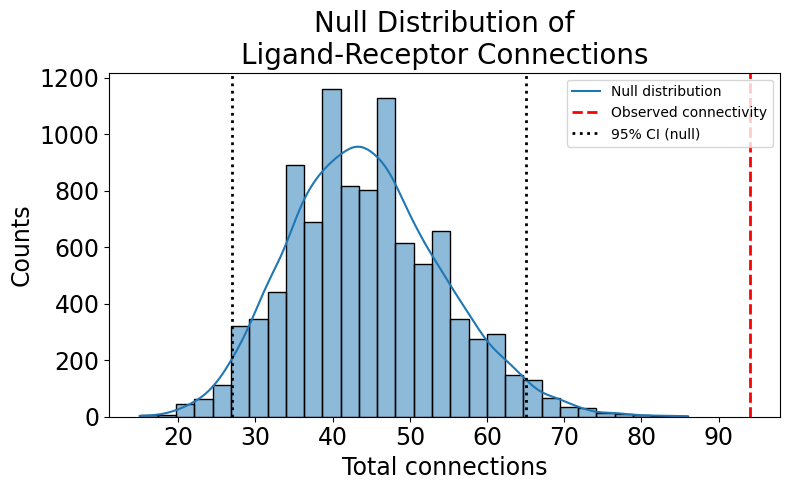

In [12]:
cat = "Ligand-Receptor"

arr = np.array(null_total_connections[cat], dtype=float)
obs = thresholds_df.loc[thresholds_df["directionality"] == cat, "true_total_connections"].iloc[0]
lo = thresholds_df.loc[thresholds_df["directionality"] == cat,"null_total_connections_CI_low_2p5"].iloc[0]
hi = thresholds_df.loc[thresholds_df["directionality"] == cat, "null_total_connections_CI_hi_97p5"].iloc[0]

print(lo, hi)

plt.figure(figsize=(8, 5))
sns.histplot(arr, bins=30, kde=True)

plt.axvline(obs, linestyle="--", linewidth=2, color="red")
plt.axvline(lo, linestyle=":", color="black", linewidth=2)
plt.axvline(hi, linestyle=":", color="black", linewidth=2)

plt.title("Null Distribution of\nLigand-Receptor Connections", fontsize=20)
plt.ylabel("Counts", fontsize=17)
plt.xlabel("Total connections", fontsize=17)

plt.xticks(fontsize=17)
plt.yticks(fontsize=17)

plt.legend([
    "Null distribution",
    "Observed connectivity",
    "95% CI (null)"
])

plt.tight_layout()
plt.savefig(res_dir / "LR_binary_nulls.pdf", dpi=600)
plt.show()

2.0 17.0


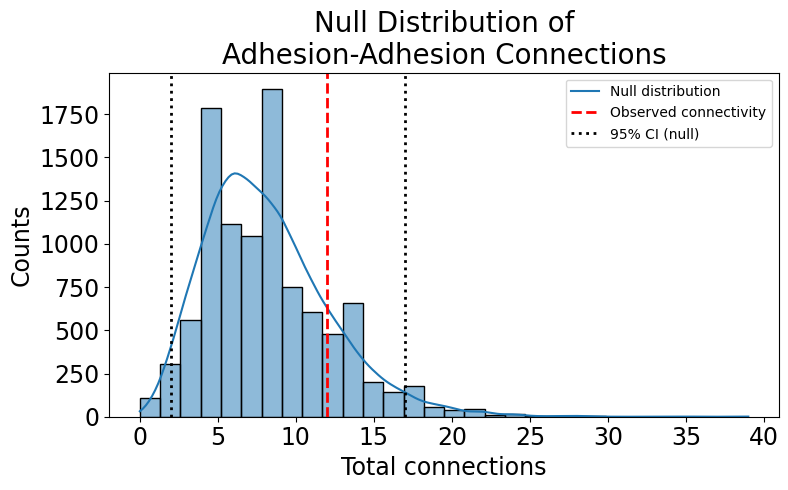

In [13]:
cat = "Adhesion-Adhesion"

arr = np.array(null_total_connections[cat], dtype=float)
obs = thresholds_df.loc[thresholds_df["directionality"] == cat, "true_total_connections"].iloc[0]
lo = thresholds_df.loc[thresholds_df["directionality"] == cat, "null_total_connections_CI_low_2p5"].iloc[0]
hi = thresholds_df.loc[thresholds_df["directionality"] == cat, "null_total_connections_CI_hi_97p5"].iloc[0]

print(lo, hi)

plt.figure(figsize=(8, 5))
sns.histplot(arr, bins=30, kde=True)

plt.axvline(obs, linestyle="--", linewidth=2, color="red")
plt.axvline(lo, linestyle=":", color="black", linewidth=2)
plt.axvline(hi, linestyle=":", color="black", linewidth=2)

plt.title("Null Distribution of\nAdhesion-Adhesion Connections", fontsize=20)
plt.ylabel("Counts", fontsize=17)
plt.xlabel("Total connections", fontsize=17)

plt.xticks(fontsize=17)
plt.yticks(fontsize=17)

plt.legend([
    "Null distribution",
    "Observed connectivity",
    "95% CI (null)"
])

plt.tight_layout()
plt.savefig(res_dir / "Adhesion_binary_nulls.pdf", dpi=600)
plt.show()